In [2]:
# Install DuckDB if not pre-installed
!pip install duckdb -q

import duckdb
import pandas as pd

# Set Pandas display options to view full table outputs easily
pd.set_option('display.max_columns', None)
print("DuckDB & Pandas successfully loaded!")

DuckDB & Pandas successfully loaded!


In [3]:
import os

# Define the directory where Kaggle places the dataset
dataset_path = '/kaggle/input/datasets/olistbr/brazilian-ecommerce'

# Connect to an in-memory DuckDB database
con = duckdb.connect(database=':memory:')

# Automatically load each CSV as an SQL table
for file in os.listdir(dataset_path):
    if file.endswith('.csv'):
        table_name = file.replace('olist_', '').replace('_dataset.csv', '').replace('.csv', '')
        file_path = os.path.join(dataset_path, file)
        
        # Read CSV and register as DuckDB table
        con.execute(f"CREATE TABLE {table_name} AS SELECT * FROM read_csv_auto('{file_path}')")
        print(f"Registered SQL table: '{table_name}'")

Registered SQL table: 'customers'
Registered SQL table: 'sellers'
Registered SQL table: 'order_reviews'
Registered SQL table: 'order_items'
Registered SQL table: 'products'
Registered SQL table: 'geolocation'
Registered SQL table: 'product_category_name_translation'
Registered SQL table: 'orders'
Registered SQL table: 'order_payments'


In [4]:
# Helper function to run SQL queries and return Pandas DataFrames for clean rendering
def run_sql(query):
    return con.execute(query).df()

# See all registered tables
run_sql("SHOW TABLES;")

,name
0,customers
1,geolocation
2,order_items
3,order_payments
4,order_reviews
5,orders
6,product_category_name_translation
7,products
8,sellers


In [5]:
# Inspect schema of the orders table
run_sql("PRAGMA table_info('orders');")

,cid,name,type,notnull,dflt_value,pk
0,0,order_id,VARCHAR,False,None,False
1,1,customer_id,VARCHAR,False,None,False
2,2,order_status,VARCHAR,False,None,False
3,3,order_purchase_timestamp,TIMESTAMP,False,None,False
4,4,order_approved_at,TIMESTAMP,False,None,False
5,5,order_delivered_carrier_date,TIMESTAMP,False,None,False
6,6,order_delivered_customer_date,TIMESTAMP,False,None,False
7,7,order_estimated_delivery_date,TIMESTAMP,False,None,False


In [6]:
# View the first 5 records of the orders table
run_sql("SELECT * FROM orders LIMIT 5;")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [7]:
query_master = """
SELECT
    o.order_id,
    c.customer_unique_id,
    c.customer_city,
    c.customer_state,
    o.order_status,
    o.order_purchase_timestamp,
    p.product_category_name,
    oi.price,
    oi.freight_value
FROM orders o
JOIN customers c
    ON o.customer_id = c.customer_id
JOIN order_items oi
    ON o.order_id = oi.order_id
JOIN products p
    ON oi.product_id = p.product_id
"""

df_master = run_sql(query_master)

print(f"Master View Shape: {df_master.shape}")
display(df_master.head())

Master View Shape: (112650, 9)


,order_id,customer_unique_id,customer_city,customer_state,order_status,order_purchase_timestamp,product_category_name,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,delivered,2017-10-02 10:56:33,utilidades_domesticas,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,barreiras,BA,delivered,2018-07-24 20:41:37,perfumaria,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,delivered,2018-08-08 08:38:49,automotivo,159.90,19.22
3,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,delivered,2018-02-13 21:18:39,papelaria,19.90,8.72
4,a4591c265e18cb1dcee52889e2d8acc3,80bb27c7c16e8f973207a5086ab329e2,congonhinhas,PR,delivered,2017-07-09 21:57:05,automotivo,147.90,27.36


In [8]:
query_revenue = """
WITH OrderFinancials AS (
    SELECT 
        p.product_category_name,
        (oi.price + oi.freight_value) AS total_order_value
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN products p ON oi.product_id = p.product_id
        WHERE o.order_status = 'delivered'
)

SELECT
    product_category_name,
    COUNT(*) AS total_items_sold,
    ROUND(SUM(total_order_value), 2) AS total_revenue
FROM OrderFinancials
WHERE product_category_name IS NOT NULL
GROUP BY product_category_name
ORDER BY total_revenue DESC
LIMIT 10;
"""

run_sql(query_revenue)

,product_category_name,total_items_sold,total_revenue
0,beleza_saude,9465,1412089.53
1,relogios_presentes,5859,1264333.12
2,cama_mesa_banho,10953,1225209.26
3,esporte_lazer,8431,1118256.91
4,informatica_acessorios,7644,1032723.77
5,moveis_decoracao,8160,880329.92
6,utilidades_domesticas,6795,758392.25
7,cool_stuff,3718,691680.89
8,automotivo,4140,669454.75
9,ferramentas_jardim,4268,567145.68


In [9]:
run_sql("""
    DROP TABLE IF EXISTS greetings;
    
    CREATE TABLE greetings (
        id INT PRIMARY KEY,
        message VARCHAR(255)
    );
    
    INSERT INTO greetings(id, message)
    VALUES (1, 'Hello, World!');
    
    SELECT message FROM greetings;
    """)

,message
0,"Hello, World!"


In [10]:
run_sql("SELECT * FROM greetings;")

,id,message
0,1,"Hello, World!"


In [11]:
run_sql("""
    DROP TABLE IF EXISTS greetings;
    
    CREATE TABLE greetings (
        id INT,
        message VARCHAR(255),
        language VARCHAR(50)
    );
    
    INSERT INTO greetings VALUES
    (1, 'Hello', 'English'),
    (2, 'Hola', 'Spanish'),
    (3, 'Bonjour', 'French'),
    (4, 'Namaste', 'Hindi'),
    (5, '...', NULL),
    (6, 'Hi', 'English');
    
    SELECT
        COUNT(*) AS total_rows,
        COUNT(language) AS rows_with_language,
        COUNT (DISTINCT language) AS unique_languages
    FROM greetings;
""")

,total_rows,rows_with_language,unique_languages
0,6,5,4


In [12]:
run_sql("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(language) AS rows_with_language,
        COUNT (DISTINCT language) AS unique_languages
    FROM greetings;
""")

,total_rows,rows_with_language,unique_languages
0,6,5,4


In [13]:
run_sql("SELECT * FROM greetings LIMIT 5;")

,id,message,language
0,1,Hello,English
1,2,Hola,Spanish
2,3,Bonjour,French
3,4,Namaste,Hindi
4,5,...,None


In [14]:
run_sql("""
    SELECT 
        order_id,
        customer_id,
        order_status,
        order_purchase_timestamp
    FROM orders
    WHERE order_status = 'canceled'
    LIMIT 10;
""")

,order_id,customer_id,order_status,order_purchase_timestamp
0,1b9ecfe83cdc259250e1a8aca174f0ad,6d6b50b66d79f80827b6d96751528d30,canceled,2018-08-04 14:29:27
1,714fb133a6730ab81fa1d3c1b2007291,e3fe72696c4713d64d3c10afe71e75ed,canceled,2018-01-26 21:34:08
2,3a129877493c8189c59c60eb71d97c29,0913cdce793684e52bbfac69d87e91fd,canceled,2018-01-25 13:34:24
3,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39
4,ed3efbd3a87bea76c2812c66a0b32219,191984a8ba4cbb2145acb4fe35b69664,canceled,2018-09-20 13:54:16
5,0966b61e30c4a07edbd7523f59b3f3e4,2fcc597b8934d99715dbfff7909dd27f,canceled,2018-05-22 18:50:55
6,9021cf1919f615a121410790dcce848f,7acf55df0298e1d2c31200fb4f6fb93b,canceled,2018-07-04 16:05:56
7,df8282afe61008dc26c6c31011474d02,aa797b187b5466bc6925aaaa4bb3bed1,canceled,2017-03-04 12:14:30
8,a39d3db795a5cf4c8b6c9dd050f0d326,ec66df2cb66dfda07c03050470e21f69,canceled,2017-03-13 16:12:24
9,8d4c637f1accf7a88a4555f02741e606,b1dd715db389a2077f43174e7a675d07,canceled,2018-08-29 16:27:49


In [15]:
run_sql("""
    SELECT 
        order_id,
        payment_type,
        payment_installments,
        payment_value
    FROM order_payments
    ORDER BY payment_value DESC
    LIMIT 5;
""")

,order_id,payment_type,payment_installments,payment_value
0,03caa2c082116e1d31e67e9ae3700499,credit_card,1,13664.08
1,736e1922ae60d0d6a89247b851902527,boleto,1,7274.88
2,0812eb902a67711a1cb742b3cdaa65ae,credit_card,8,6929.31
3,fefacc66af859508bf1a7934eab1e97f,boleto,1,6922.21
4,f5136e38d1a14a4dbd87dff67da82701,boleto,1,6726.66


In [16]:
run_sql("""
    SELECT 
        order_status,
        COUNT(*) AS  total_orders
    FROM orders
    GROUP BY order_status
    ORDER BY total_orders DESC;
""")

,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [17]:
run_sql("""
    SELECT 
        COUNT(*) AS total_transactions,
        SUM(payment_value) AS total_revenue,
        AVG(payment_value) AS average_order_value
    FROM order_payments;
""")

,total_transactions,total_revenue,average_order_value
0,103886,1.600887e+07,154.10038


In [18]:
run_sql("""
    SELECT 
        payment_type,
        COUNT(*) AS total_high_value_transactions,
        SUM(payment_value) AS total_revenue
    FROM order_payments
    WHERE payment_value > 500
    GROUP BY payment_type
    ORDER BY total_revenue DESC;
""")

,payment_type,total_high_value_transactions,total_revenue
0,credit_card,3488,3201957.77
1,boleto,678,645074.69
2,debit_card,44,51376.52
3,voucher,46,43813.57


In [19]:
run_sql("""
    SELECT 
        payment_type,
        COUNT(*) AS total_high_value_transactions,
        SUM(payment_value) AS total_revenue
    FROM order_payments
    WHERE payment_value > 500
    GROUP BY payment_type
    HAVING COUNT(*) > 1000
    ORDER BY total_revenue DESC;
""")

,payment_type,total_high_value_transactions,total_revenue
0,credit_card,3488,3201957.77


In [20]:
run_sql("""
    SELECT 
        o.order_id,
        o.order_status,
        c.customer_city,
        c.customer_state
    FROM orders o
    INNER JOIN customers c
        ON o.customer_id = c.customer_id
    LIMIT 10;
""")

,order_id,order_status,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,vianopolis,GO
3,ad21c59c0840e6cb83a9ceb5573f8159,delivered,santo andre,SP
4,a4591c265e18cb1dcee52889e2d8acc3,delivered,congonhinhas,PR
5,136cce7faa42fdb2cefd53fdc79a6098,invoiced,santa rosa,RS
6,6514b8ad8028c9f2cc2374ded245783f,delivered,nilopolis,RJ
7,76c6e866289321a7c93b82b54852dc33,delivered,faxinalzinho,RS
8,e69bfb5eb88e0ed6a785585b27e16dbf,delivered,sorocaba,SP
9,e6ce16cb79ec1d90b1da9085a6118aeb,delivered,rio de janeiro,RJ


In [21]:
run_sql("""
    SELECT 
        c.customer_city,
        c.customer_state,
        COUNT(o.order_id) AS total_orders
    FROM orders o
    INNER JOIN customers c
        ON o.customer_id = c.customer_id
    GROUP BY c.customer_city, c.customer_state
    ORDER BY total_orders DESC
    LIMIT 10;
""")

,customer_city,customer_state,total_orders
0,sao paulo,SP,15540
1,rio de janeiro,RJ,6882
2,belo horizonte,MG,2773
3,brasilia,DF,2131
4,curitiba,PR,1521
5,campinas,SP,1444
6,porto alegre,RS,1379
7,salvador,BA,1245
8,guarulhos,SP,1189
9,sao bernardo do campo,SP,938


In [22]:
run_sql("""
    SELECT 
        c.customer_city,
        c.customer_state,
        COUNT(DISTINCT o.order_id) AS total_orders,
        ROUND(SUM(oi.price + oi.freight_value),2) AS total_revenue
    FROM orders o
    INNER JOIN customers c
        ON o.customer_id = c.customer_id
    INNER JOIN order_items oi
        ON o.order_id = oi.order_id
    GROUP BY c.customer_city, c.customer_state
    ORDER BY total_revenue DESC
    LIMIT 10;
""")

,customer_city,customer_state,total_orders,total_revenue
0,sao paulo,SP,15402,2170227.12
1,rio de janeiro,RJ,6834,1154234.02
2,belo horizonte,MG,2750,416733.39
3,brasilia,DF,2116,352305.14
4,curitiba,PR,1510,244739.87
5,porto alegre,RS,1372,224064.09
6,salvador,BA,1238,216772.40
7,campinas,SP,1429,212541.70
8,guarulhos,SP,1178,163575.82
9,niteroi,RJ,845,137919.38


In [23]:
run_sql("""
    SELECT 
        o.order_id,
        c.customer_city,
        oi.order_item_id,
        p.product_category_name,
        oi.price,
        oi.freight_value
    FROM orders o
    INNER JOIN customers c
        ON o.customer_id = c.customer_id
    INNER JOIN order_items oi
        ON o.order_id = oi.order_id
    INNER JOIN products p
        ON oi.product_id = p.product_id
        
    WHERE o.order_id = (
        SELECT order_id
        FROM order_items
        GROUP BY order_id
        HAVING COUNT(*) = 4
        LIMIT 1
    );
""")

,order_id,customer_city,order_item_id,product_category_name,price,freight_value
0,0d193d461bbcef442c5e6786a16d5bca,sao paulo,1,telefonia,29.9,11.85
1,0d193d461bbcef442c5e6786a16d5bca,sao paulo,2,telefonia,29.9,11.85
2,0d193d461bbcef442c5e6786a16d5bca,sao paulo,3,telefonia,29.9,11.85
3,0d193d461bbcef442c5e6786a16d5bca,sao paulo,4,telefonia,29.9,11.85


In [24]:
run_sql("""
    WITH OrderTotals AS(
        SELECT 
            order_id,
            SUM(price + freight_value) AS total_order_value,
            COUNT(order_item_id) AS items_in_cart
        FROM order_items
        GROUP BY order_id
    )

    SELECT 
        c.customer_city,
        c.customer_state,
        COUNT(o.order_id) AS total_orders,
        ROUND(SUM(ot.total_order_value), 2) AS city_revenue
    FROM orders o
    INNER JOIN customers c
        ON o.customer_id = c.customer_id
    INNER JOIN OrderTotals ot
        ON o.order_id = ot.order_id
    GROUP BY c.customer_city, c.customer_state
    ORDER BY city_revenue DESC
    LIMIT 10;
""")

,customer_city,customer_state,total_orders,city_revenue
0,sao paulo,SP,15402,2170227.12
1,rio de janeiro,RJ,6834,1154234.02
2,belo horizonte,MG,2750,416733.39
3,brasilia,DF,2116,352305.14
4,curitiba,PR,1510,244739.87
5,porto alegre,RS,1372,224064.09
6,salvador,BA,1238,216772.40
7,campinas,SP,1429,212541.70
8,guarulhos,SP,1178,163575.82
9,niteroi,RJ,845,137919.38


In [25]:
run_sql("""
    WITH OrderTotals AS (
        SELECT 
            order_id,
            SUM(price + freight_value) AS total_order_value
        FROM order_items
        GROUP BY order_id
    ),

    TopCities AS (
        SELECT 
            c.customer_city,
            COUNT(o.order_id) AS total_orders
        FROM orders o
        INNER JOIN customers c ON o.customer_id = c.customer_id
        GROUP BY c.customer_city
        HAVING COUNT(o.order_id) > 1000
    )

    SELECT
        tc.customer_city,
        tc.total_orders,
        ROUND(AVG(ot.total_order_value), 2) AS average_order_value
    FROM TopCities tc
    INNER JOIN customers c ON tc.customer_city = c.customer_city
    INNER JOIN orders o ON c.customer_id = o.customer_id
    INNER JOIN OrderTotals ot ON o.order_id = ot.order_id
    GROUP BY tc.customer_city, tc.total_orders
    ORDER BY average_order_value DESC;
""")

,customer_city,total_orders,average_order_value
0,salvador,1245,175.10
1,rio de janeiro,6882,168.90
2,brasilia,2131,166.50
3,porto alegre,1379,163.31
4,curitiba,1521,162.08
5,belo horizonte,2773,151.54
6,campinas,1444,148.73
7,sao paulo,15540,140.91
8,guarulhos,1189,138.86


In [26]:
run_sql("""
    WITH Raw_RFM AS (
        SELECT 
            c.customer_unique_id,
            MAX(o.order_purchase_timestamp) AS last_purchase_date,
            COUNT(DISTINCT o.order_id) AS frequency,
            SUM(oi.price + oi.freight_value) AS monetary
        FROM customers c
        INNER JOIN orders o
            ON c.customer_id = o.customer_id
        INNER JOIN order_items oi
            ON o.order_id = oi.order_id
        GROUP BY c.customer_unique_id
    ),

    RFM_Scores AS (
        SELECT 
            customer_unique_id,
            last_purchase_date,
            frequency,
            ROUND(monetary, 2) AS monetary,

            NTILE(5) OVER(ORDER BY last_purchase_date DESC) AS r_score,

            NTILE(5) OVER(ORDER BY frequency DESC) AS f_score,

            NTILE(5) OVER(ORDER BY monetary DESC) AS m_score

        FROM Raw_RFM
    )

    SELECT *
    FROM RFM_Scores
    WHERE m_score = 5 AND r_score = 5
    ORDER BY monetary DESC
    LIMIT 10;
""")

,customer_unique_id,last_purchase_date,frequency,monetary,r_score,f_score,m_score
0,89fd593957ef80a12f0588913e78b00d,2017-05-27 04:22:55,1,55.28,5,3,5
1,a4ab5f34ede13ac71145acd2fe5447d5,2017-07-28 10:29:15,1,55.27,5,2,5
2,4f24d302b7c54fe31fbbfdcf6ef9ff39,2017-02-09 10:05:12,1,55.19,5,3,5
3,8e0aa7241f92784858314b4093ad73aa,2017-05-07 21:00:57,1,55.18,5,3,5
4,dc5aa19797b8fb7a4929ad109fb25553,2017-05-17 23:19:34,1,55.12,5,3,5
5,ae81c8b1f631eb3108924289a3333c0b,2017-01-16 23:03:40,1,55.11,5,5,5
6,01be09e08ce97be4356a7c93bda4ee70,2017-05-18 09:56:49,1,55.11,5,3,5
7,0519ff2bbd00936c93d0f5e4db794a71,2017-08-10 22:11:07,1,55.10,5,2,5
8,08956f78b05a629117296cd7fea74142,2017-08-07 21:01:57,1,55.10,5,2,5
9,979f3bf020fee365ea741df1468b620e,2017-08-07 17:26:19,1,55.10,5,2,5


**Phase 3**

In [27]:
# 1. Extract raw data from SQL into a Pandas DataFrame
query_ml = """
    SELECT 
        c.customer_unique_id,
        MAX(o.order_purchase_timestamp) AS last_purchase_date,
        COUNT(DISTINCT o.order_id) AS frequency,
        SUM(oi.price + oi.freight_value) AS monetary
    FROM customers c
    INNER JOIN orders o ON c.customer_id = o.customer_id
    INNER JOIN order_items oi ON o.order_id = oi.order_id
    GROUP BY c.customer_unique_id
"""

# run_sql() automatically returns a Pandas DataFrame!
df_rfm = run_sql(query_ml)

# Calculate 'Recency' in pure Python (Days since last purchase)
df_rfm['last_purchase_date'] = pd.to_datetime(df_rfm['last_purchase_date'])
max_date = df_rfm['last_purchase_date'].max()
df_rfm['recency'] = (max_date - df_rfm['last_purchase_date']).dt.days

# Isolate just the numeric columns for our Machine Learning model
df_ml = df_rfm[['recency', 'frequency', 'monetary']].copy()

print(f"Data ready for ML. Shape: {df_ml.shape}")
display(df_ml.head())

Data ready for ML. Shape: (95420, 3)


,recency,frequency,monetary
0,474,1,75.16
1,349,1,118.86
2,28,1,53.66
3,354,1,59.34
4,199,2,267.60


In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

ml_scaled = scaler.fit_transform(df_ml)

df_scaled = pd.DataFrame(ml_scaled, columns = df_ml.columns)
display(df_scaled.head())

,recency,frequency,monetary
0,1.510841,-0.161045,-0.398040
1,0.694698,-0.161045,-0.206641
2,-1.401156,-0.161045,-0.492207
3,0.727344,-0.161045,-0.467329
4,-0.284673,4.573066,0.444815


In [29]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state = 42, n_init = 10)

df_rfm['cluster'] = kmeans.fit_predict(df_scaled)

cluster_summary = df_rfm.groupby('cluster')[['recency', 'frequency', 'monetary']].mean().round(1)
display(cluster_summary)


,recency,frequency,monetary
cluster,,,
0,132.5,1.0,134.6
1,392.7,1.0,134.0
2,225.2,2.1,289.6
3,244.9,1.0,1166.6


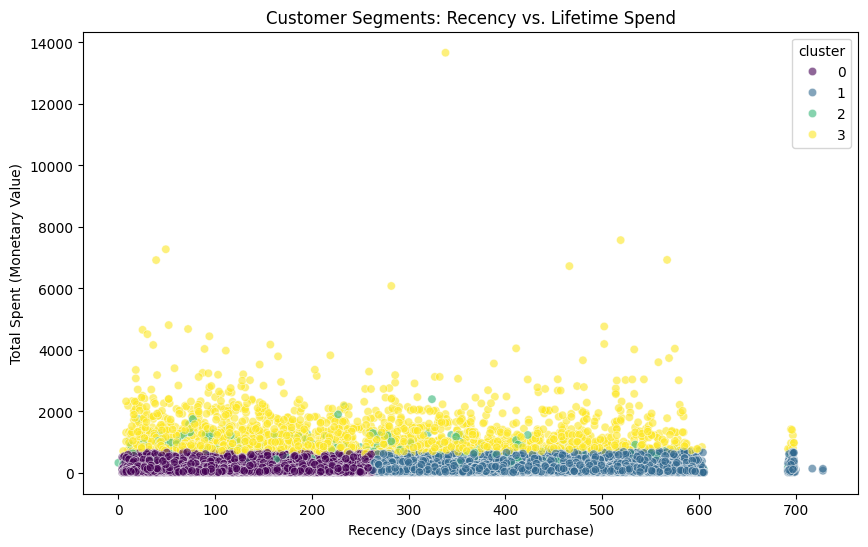

In [30]:
# 4. Plot the Customer Segments
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_rfm, 
    x='recency', 
    y='monetary', 
    hue='cluster', 
    palette='viridis', 
    alpha=0.6
)
plt.title('Customer Segments: Recency vs. Lifetime Spend')
plt.xlabel('Recency (Days since last purchase)')
plt.ylabel('Total Spent (Monetary Value)')
plt.show()

In [33]:
# 1. Extract ML features via SQL
query_clf = """
    SELECT 
        o.order_id,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date,
        SUM(oi.freight_value) AS total_freight,
        SUM(p.product_weight_g) AS total_weight_g
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN products p ON oi.product_id = p.product_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
    GROUP BY 
        o.order_id,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date
"""

df_clf = run_sql(query_clf)
print(f"Dataset shape: {df_clf.shape}")

Dataset shape: (96470, 5)


In [34]:
df_clf['actual_date'] = pd.to_datetime(df_clf['order_delivered_customer_date'])
df_clf['est_date'] = pd.to_datetime(df_clf['order_estimated_delivery_date'])

df_clf['is_late'] = (df_clf['actual_date'] > df_clf['est_date']).astype(int)

print("Class Balance (Late vs On-Time):")
print(df_clf['is_late'].value_counts(normalize = True).round(3))

X = df_clf[['total_freight', 'total_weight_g']]
y = df_clf['is_late']

Class Balance (Late vs On-Time):
is_late
0    0.919
1    0.081
Name: proportion, dtype: float64


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training rows: {len(X_train_scaled)}, Testing rows: {len(X_test_scaled)}")

Training rows: 77176, Testing rows: 19294


In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf_model = RandomForestClassifier(n_estimators=100, max_depth = 5, class_weight = 'balanced', random_state = 42)
rf_model.fit(X_train_scaled, y_train)

y_pred = rf_model.predict(X_test_scaled)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.39      0.55     17746
           1       0.09      0.69      0.16      1548

    accuracy                           0.41     19294
   macro avg       0.51      0.54      0.35     19294
weighted avg       0.87      0.41      0.52     19294



/tmp/ipykernel_49/237572902.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importance, x='Importance', y='Feature', palette='mako')


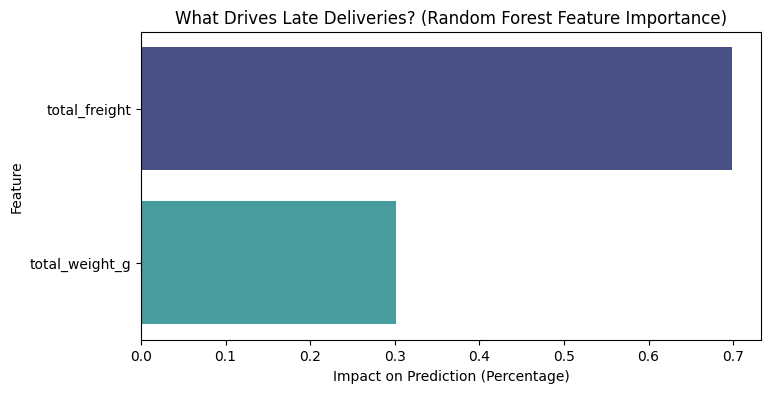

In [37]:
# 5. Extract and Plot Feature Importances
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Get the importance numbers from our trained model
importances = rf_model.feature_importances_
feature_names = X.columns

# Bundle them into a clean Pandas DataFrame and sort them
df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot the results
plt.figure(figsize=(8, 4))
sns.barplot(data=df_importance, x='Importance', y='Feature', palette='mako')
plt.title('What Drives Late Deliveries? (Random Forest Feature Importance)')
plt.xlabel('Impact on Prediction (Percentage)')
plt.ylabel('Feature')
plt.show()